# Aditya-L1 Solar Flare **Nowcast** — streaming detection engine

**Question answered:** *Is a flare happening right now, when did it start, and how big is it?*

This notebook builds, tunes, validates and streams the nowcasting stage of the Aditya-L1 space-weather pipeline.
It is the improved successor of Team Phoenix's six-script nowcast (`phase1_ingest_align.py` … `phase6_classify.py`),
rebuilt as **one streaming engine** (`l1_nowcast/`) that processes one sample at a time — so the same code runs
on a live feed and in back-tests.

| | Team Phoenix nowcast | This engine |
|---|---|---|
| Execution | batch scripts over a whole CSV | incremental, one sample at a time (live-capable); batch = the same engine in a loop |
| Background | 2-pass rolling median/MAD | causal *flare-masked* robust background (only quiet samples admitted), with stale re-seed |
| Onset rule | threshold crossing | threshold **and** sustained rise (NOAA-style), plus a rise guard that rejects noise on decaying tails |
| Flare end / overlap | bridge 60 s, min 60 s | NOAA end rule (half-way back to pre-flare flux) + new flare on the decaying tail of the previous one |
| Classes | counts-proxy A–X ranking | true GOES classes for flux channels; counts→flux cross-calibration for SoLEXS |
| Validation | 4 known X-flares | full match against **NOAA's official flare list** (2,131 flares), tuned on Jan–Apr, tested on May–Oct |
| Inputs | two fixed CSVs, hard-coded `D:\` paths | SoLEXS/HEL1OS CSV, OGIP FITS (ISSDC), watched folder, GOES archive, **GOES live feed** |

### About "live Aditya-L1 data"
ISRO does not offer a public real-time Aditya-L1 API: SoLEXS and HEL1OS data are released as Level-1/2 **files** through ISSDC's
[PRADAN](https://pradan.issdc.gov.in) portal (login required). The engine therefore ingests Aditya-L1 through file readers and a
**directory watcher** (drop new files in a folder → they stream in). For a genuinely live solar X-ray stream it uses NOAA's
**GOES-19 XRS** feed — the same physical measurement class as SoLEXS (thermal soft X-rays) — which is also what this notebook trains
and validates on, because it comes with an official, independent flare catalogue to score against. The analysis window
(Jan 1 – Oct 27 2026) contains the exact Mar 1 – Jun 25 period of the team's Aditya-L1 dataset.

In [1]:
import sys, json, time, math, datetime as dt, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sys.path.insert(0, str(Path.cwd()))
from l1_nowcast import *
from l1_nowcast.detector import QUIET, FLARE, DECAY

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

DATA = Path("data") / "goes"          # GOES archive cache (git-ignored)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)

# ---- configuration -------------------------------------------------------
GOES_SATELLITE = 19
START, END = dt.date(2026, 1, 1), dt.date(2026, 10, 27)
DEV_END = pd.Timestamp("2026-05-01")      # tune on Jan-Apr, report on May-Oct (never seen while tuning)
ADITYA_WINDOW = ("2026-03-01", "2026-06-26")
RUN_LIVE = True                           # poll the real NOAA SWPC feed in section 9

# Point these at the Team Phoenix exports to run the Aditya-L1 path on real data (section 10)
SOLEXS_CSV = None   # e.g. r"D:\Team_Pheonix_PS15\combined_solexs_dataset.csv"
HEL1OS_CSV = None   # e.g. r"D:\Team_Pheonix_PS15\combined_hel1os_dataset_full.csv"
print("l1_nowcast", __import__("l1_nowcast").__version__)

l1_nowcast 1.0.0


## 1. Data: GOES-19 XRS science archive (NCEI) + NOAA's official flare list
`download_goes_archive` fetches the 1-minute L2 science files (`avg1m`) and NOAA's flare-summary files (`flsum`) for every day
(already-downloaded files are skipped). Quality flags are applied on load (eclipse / bad-data minutes → NaN) and the result is
put on a complete 1-minute grid, so every gap is an explicit NaN row — never a silent jump.

In [2]:
t0 = time.time()
stats = download_goes_archive(DATA, START, END, satellite=GOES_SATELLITE)
print("download:", stats, f"({time.time()-t0:.0f}s)")
xrs = load_goes_avg1m(DATA / "avg1m")
ref = load_goes_flare_summary(DATA / "flsum")
missing_ref = missing_reference_days(DATA / "flsum", START, END)
print(f"XRS minutes: {len(xrs):,}  ({xrs.index.min()} -> {xrs.index.max()})")
print(f"NOAA reference flares: {len(ref):,}; days without a flare-summary file (excluded from scoring): "
      f"{[d.strftime('%Y-%m-%d') for d in missing_ref]}")
xrs.describe().T

download: {'downloaded': 0, 'cached': 594, 'missing': 6} (1s)


XRS minutes: 432,000  (2026-01-01 00:00:00 -> 2026-10-27 23:59:00)
NOAA reference flares: 2,131; days without a flare-summary file (excluded from scoring): ['2026-03-07', '2026-07-16', '2026-07-17', '2026-08-07', '2026-09-17', '2026-09-18']


,count,mean,std,min,25%,50%,75%,max
xrsa,419124.0,1.078160e-07,0.000002,1.000000e-09,1.409669e-08,2.169685e-08,3.787878e-08,0.000340
xrsb,419124.0,1.490412e-06,0.000006,1.519352e-07,4.871350e-07,7.938548e-07,1.247128e-06,0.000836


### 1a. Coverage audit (the same checks Team Phoenix ran on SoLEXS/HEL1OS)

      completeness_%   median      p99      max
xrsa              97 2.17e-08  1.3e-06  0.00034
xrsb              97 7.94e-07 1.33e-05 0.000836


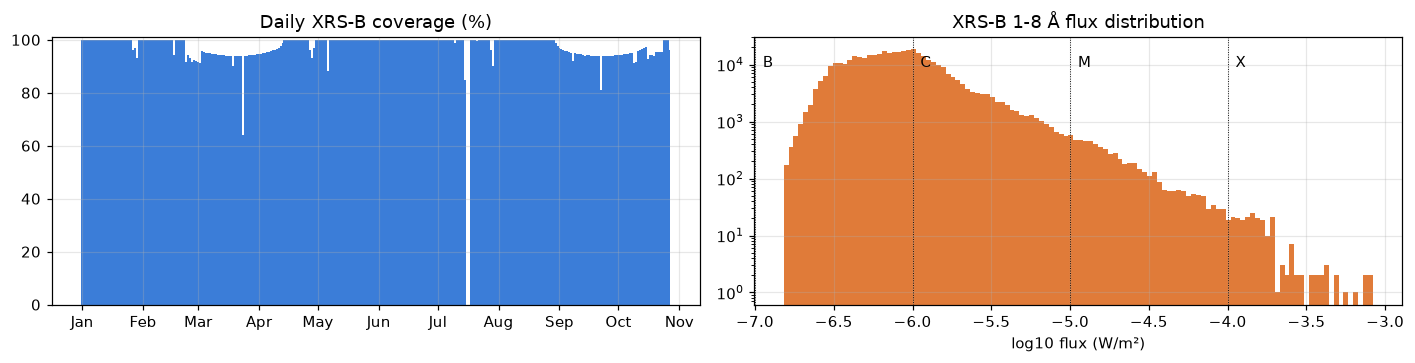

In [3]:
cov = pd.DataFrame({
    "completeness_%": xrs.notna().mean() * 100,
    "median": xrs.median(), "p99": xrs.quantile(0.99), "max": xrs.max(),
})
print(cov.to_string(float_format=lambda v: f"{v:.3g}"))
daily = xrs["xrsb"].notna().resample("D").mean() * 100
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].bar(daily.index, daily.values, width=1.0, color="#3b7dd8")
ax[0].set(title="Daily XRS-B coverage (%)", ylim=(0, 101)); ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
lb = np.log10(xrs["xrsb"].dropna())
ax[1].hist(lb, bins=120, color="#e07b39"); ax[1].set_yscale("log")
for v, lab in zip([-7, -6, -5, -4], "BCMX"):
    ax[1].axvline(v, color="k", lw=0.6, ls=":"); ax[1].text(v + 0.05, ax[1].get_ylim()[1] * 0.3, lab)
ax[1].set(title="XRS-B 1-8 Å flux distribution", xlabel="log10 flux (W/m²)")
plt.tight_layout(); plt.savefig(FIG / "coverage_and_flux_hist.png"); plt.show()

In [4]:
ref["letter"] = ref["flare_class"].str[0]
print("NOAA flares by class:", ref["letter"].value_counts().reindex(list("ABCMX")).fillna(0).astype(int).to_dict())
# The 4 X-flares Team Phoenix used as ground truth in calib_check.py:
known_x = {"2026-03-30": "X1.5", "2026-04-23": "X2.4", "2026-04-24": "X2.5", "2026-06-03": "X1.0"}
xr = ref[ref["letter"] == "X"][["start", "peak", "end", "flare_class"]]
xr["in_team_calib_check"] = xr["peak"].dt.strftime("%Y-%m-%d").map(lambda d: known_x.get(d, ""))
xr

NOAA flares by class: {'A': 0, 'B': 434, 'C': 1477, 'M': 207, 'X': 13}


,start,peak,end,flare_class,in_team_calib_check
127,2026-01-18 17:27:00,2026-01-18 18:09:00,2026-01-18 18:50:00,X1.9,
228,2026-02-01 12:24:00,2026-02-01 12:33:00,2026-02-01 12:37:00,X1.0,
237,2026-02-01 23:44:00,2026-02-01 23:57:00,2026-02-02 00:04:00,X8.3,
238,2026-02-02 00:31:00,2026-02-02 00:36:00,2026-02-02 00:39:00,X2.9,
244,2026-02-02 07:39:00,2026-02-02 08:14:00,2026-02-02 08:39:00,X1.6,
263,2026-02-03 13:58:00,2026-02-03 14:08:00,2026-02-03 14:18:00,X1.5,
283,2026-02-04 12:02:00,2026-02-04 12:13:00,2026-02-04 12:18:00,X4.3,
586,2026-03-30 02:47:00,2026-03-30 03:19:00,2026-03-30 03:44:00,X1.5,X1.5
798,2026-04-24 00:51:00,2026-04-24 01:07:00,2026-04-24 01:13:00,X2.5,X2.5
802,2026-04-24 08:01:00,2026-04-24 08:14:00,2026-04-24 08:18:00,X2.5,X2.5


## 2. Method
Per channel, every sample goes through **background → threshold → state machine**:

```
background : trailing 2 h window of log10(flux); median + IQR/1.349, built ONLY from samples that were quiet when they arrived
             (the causal version of the team's two-pass fix — a long flare can never raise its own background).
             If no quiet sample is seen for 6 h the window is re-seeded, so a permanent baseline step cannot lock the detector.
threshold  : bg_median + max(k·σ, log10(min_ratio))

QUIET --(confirm samples above threshold AND flux ≥ onset_min_rise × min(last 5))--> FLARE      (level trigger)
QUIET --(rise_samples consecutive increases totalling ≥ rise_ratio)----------------> FLARE      (rise trigger, NOAA-style)
FLARE --(flux ≤ bg + ½(peak − bg))---------------------------------------------------> DECAY  (flare closed: NOAA end rule)
FLARE --(sustained re-rise after the peak)-------------------------------------------> FLARE  (old flare closed, new one opened)
FLARE --(below threshold > 3 min, or data gap)----------------------------------------> QUIET
DECAY --(sustained rise)---------------------------------------------------------------> FLARE  (new flare on the decaying tail)
DECAY --(back below threshold)----------------------------------------------------------> QUIET
```
A flare's **start** is retrospective (beginning of the rise); its **detect_time** is the causal alert time.
Primary (soft, XRS-B / SoLEXS) and secondary (XRS-A / HEL1OS) events are then **fused**: a flare confirmed by both is high confidence.

## 3. Tuning on Jan–Apr 2026 (development period only)
Objective: F1 of our flares ≥ C1.0 against NOAA's list (precision = our ≥C detections that match a NOAA flare; recall = NOAA ≥C flares
we detect). Matching: interval overlap with ±5 min tolerance, one-to-one, largest flares first. May–Oct is **not touched** here.

In [5]:
dev = xrs[xrs.index < DEV_END]
ref_dev = ref[ref["start"] < DEV_END]
base = goes_channels()[0]

t0 = time.time()
print("Stage A - threshold & onset guard")
gA = tune_channel(dev, ref_dev, base, {"k_sigma": [1.5, 2.5, 3.5], "min_ratio": [1.2, 1.3, 1.5],
                                       "onset_min_rise": [1.0, 1.2, 1.3, 1.5]},
                  cadence_s=60, exclude_days=missing_ref, verbose=False)
bA = gA.iloc[0]
cfgA = ChannelConfig(**{**base.to_dict(), "k_sigma": bA.k_sigma, "min_ratio": bA.min_ratio, "onset_min_rise": bA.onset_min_rise})
print("Stage B - confirmation & rise trigger")
gB = tune_channel(dev, ref_dev, cfgA, {"confirm": [1, 2, 3], "rise_samples": [2, 3, 4], "rise_ratio": [1.3, 1.4, 1.6]},
                  cadence_s=60, exclude_days=missing_ref, verbose=False)
bB = gB.iloc[0]
print(f"tuning took {time.time()-t0:.0f}s")
display(gA.head(8).round(3)); display(gB.head(8).round(3))

Stage A - threshold & onset guard


Stage B - confirmation & rise trigger


tuning took 198s


,k_sigma,min_ratio,onset_min_rise,precision,recall,f1,n_detected,latency_med_min
0,1.5,1.3,1.3,0.903,0.915,0.909,773,6.0
1,1.5,1.2,1.3,0.885,0.915,0.899,789,6.0
2,2.5,1.3,1.3,0.882,0.891,0.886,770,6.0
3,2.5,1.2,1.3,0.872,0.895,0.883,782,6.0
4,1.5,1.3,1.2,0.832,0.919,0.873,843,6.0
5,2.5,1.3,1.2,0.837,0.895,0.865,815,6.0
6,1.5,1.5,1.3,0.889,0.830,0.859,713,6.0
7,1.5,1.2,1.5,0.912,0.803,0.854,673,6.0


,confirm,rise_samples,rise_ratio,precision,recall,f1,n_detected,latency_med_min
0,2,2,1.6,0.903,0.915,0.909,773,6.0
1,2,3,1.6,0.903,0.911,0.907,770,6.0
2,1,2,1.6,0.886,0.928,0.906,799,5.0
3,1,3,1.6,0.887,0.925,0.906,796,5.0
4,2,4,1.6,0.903,0.905,0.904,765,6.0
5,1,4,1.6,0.887,0.920,0.903,791,5.0
6,2,4,1.4,0.849,0.954,0.899,857,5.0
7,2,3,1.4,0.844,0.959,0.898,867,5.0


In [6]:
TUNED = {"k_sigma": float(bA.k_sigma), "min_ratio": float(bA.min_ratio), "onset_min_rise": float(bA.onset_min_rise),
         "confirm": int(bB.confirm), "rise_samples": int(bB.rise_samples), "rise_ratio": float(bB.rise_ratio)}
defaults = {k: getattr(base, k) for k in TUNED}
print("tuned   :", TUNED)
print("defaults:", defaults, "(the library defaults were set from this same procedure)")
CHANNELS = goes_channels(xrsb=TUNED)

tuned   : {'k_sigma': 1.5, 'min_ratio': 1.3, 'onset_min_rise': 1.3, 'confirm': 2, 'rise_samples': 2, 'rise_ratio': 1.6}
defaults: {'k_sigma': 1.5, 'min_ratio': 1.3, 'onset_min_rise': 1.3, 'confirm': 2, 'rise_samples': 2, 'rise_ratio': 1.6} (the library defaults were set from this same procedure)


## 4. Full run (both channels + fusion) and held-out validation (May–Oct 2026)

In [7]:
t0 = time.time()
res = run_batch(xrs, CHANNELS, cadence_s=60)
el = time.time() - t0
print(f"{len(xrs):,} samples x 2 channels in {el:.1f}s  ->  {len(xrs)/el:,.0f} samples/s "
      f"(real time needs 1/60 per s for GOES, 1 per s for Aditya-L1)")
events = res.events
prim = res.primary_events("xrsb")
print("primary (XRS-B) flares:", len(prim), "| by class:", prim["flare_class"].str[0].value_counts().reindex(list("ABCMX")).fillna(0).astype(int).to_dict())
print("fused labels:", res.fused["label"].value_counts().to_dict())
prim.head(10)

432,000 samples x 2 channels in 9.6s  ->  44,913 samples/s (real time needs 1/60 per s for GOES, 1 per s for Aditya-L1)
primary (XRS-B) flares: 2142 | by class: {'A': 0, 'B': 430, 'C': 1493, 'M': 206, 'X': 13}
fused labels: {'BOTH': 1842, 'SECONDARY_ONLY': 1209, 'PRIMARY_ONLY': 300}


,event_id,channel,start,detect_time,background,trigger,peak_time,peak,end,end_reason,fluence,n_samples,flare_class,duration_min,detect_delay_min,rise_min
0,xrsb-00001,xrsb,2026-01-01 02:15:00,2026-01-01 02:20:00,0.000001,level,2026-01-01 02:25:00,0.000010,2026-01-01 02:33:00,decay,0.004898,14,C9.7,18.0,5.0,10.0
1,xrsb-00002,xrsb,2026-01-01 03:57:00,2026-01-01 04:03:00,0.000002,level,2026-01-01 04:03:00,0.000002,2026-01-01 04:05:00,decay,0.000106,3,C2.4,8.0,6.0,6.0
2,xrsb-00003,xrsb,2026-01-01 05:56:00,2026-01-01 05:57:00,0.000002,level,2026-01-01 06:22:00,0.000004,2026-01-01 06:33:00,decay,0.002930,37,C4.4,37.0,1.0,26.0
3,xrsb-00004,xrsb,2026-01-01 06:42:00,2026-01-01 06:45:00,0.000002,level,2026-01-01 06:48:00,0.000005,2026-01-01 06:51:00,decay,0.001057,7,C5.4,9.0,3.0,6.0
4,xrsb-00005,xrsb,2026-01-01 15:10:00,2026-01-01 15:11:00,0.000001,level,2026-01-01 15:11:00,0.000002,2026-01-01 15:15:00,decay,0.000088,5,C1.6,5.0,1.0,1.0
5,xrsb-00006,xrsb,2026-01-01 15:48:00,2026-01-01 15:52:00,0.000001,level,2026-01-01 15:55:00,0.000002,2026-01-01 16:04:00,decay,0.000540,13,C2.1,16.0,4.0,7.0
6,xrsb-00007,xrsb,2026-01-01 17:18:00,2026-01-01 17:34:00,0.000001,level,2026-01-01 17:59:00,0.000006,2026-01-01 18:31:00,decay,0.011062,58,C6.3,73.0,16.0,41.0
7,xrsb-00008,xrsb,2026-01-01 21:45:00,2026-01-01 21:50:00,0.000002,rise,2026-01-01 21:50:00,0.000003,2026-01-01 21:55:00,decay,0.000304,6,C2.7,10.0,5.0,5.0
8,xrsb-00009,xrsb,2026-01-02 00:08:00,2026-01-02 00:14:00,0.000001,level,2026-01-02 00:17:00,0.000007,2026-01-02 00:23:00,decay,0.002223,10,C6.5,15.0,6.0,9.0
9,xrsb-00010,xrsb,2026-01-02 01:04:00,2026-01-02 01:05:00,0.000001,level,2026-01-02 01:05:00,0.000002,2026-01-02 01:08:00,decay,0.000082,4,C1.8,4.0,1.0,1.0


In [8]:
def period(df, col, lo, hi):
    return df[(df[col] >= pd.Timestamp(lo)) & (df[col] < pd.Timestamp(hi))]

periods = {"dev Jan-Apr (tuning)": ("2026-01-01", DEV_END), "TEST May-Oct (held out)": (DEV_END, "2026-10-28"),
           "Aditya-L1 window Mar 1-Jun 25": ADITYA_WINDOW}
reports = {}
for name, (lo, hi) in periods.items():
    reports[name] = evaluate(period(prim, "start", lo, hi), period(ref, "start", lo, hi), min_class="C1.0", exclude_days=missing_ref)
summary = pd.DataFrame({k: v.summary() for k, v in reports.items()})
summary

,dev Jan-Apr (tuning),TEST May-Oct (held out),Aditya-L1 window Mar 1-Jun 25
precision,0.902975,0.910352,0.915966
recall(POD),0.914586,0.910256,0.905556
F1,0.908744,0.910304,0.910731
detected(>=min),773.000000,937.000000,714.000000
reference(>=min),761.000000,936.000000,720.000000
class_letter_agreement,1.000000,0.998826,1.000000
alert_latency_median_min,6.000000,6.000000,6.000000
alert_latency_p90_min,8.000000,8.000000,8.000000
alert_before_peak_median_min,3.000000,3.000000,3.000000
peak_offset_median_min,0.000000,0.000000,0.000000


Held-out POD by NOAA class:


,n_reference,n_detected,POD
ref_letter,,,
B,294,247,0.840
C,834,752,0.902
M,99,97,0.980
X,3,3,1.000


Class-letter confusion (matched >= C1 flares):


nowcast,C,M,X
NOAA,,,
C,751,1,0
M,0,97,0
X,0,0,3


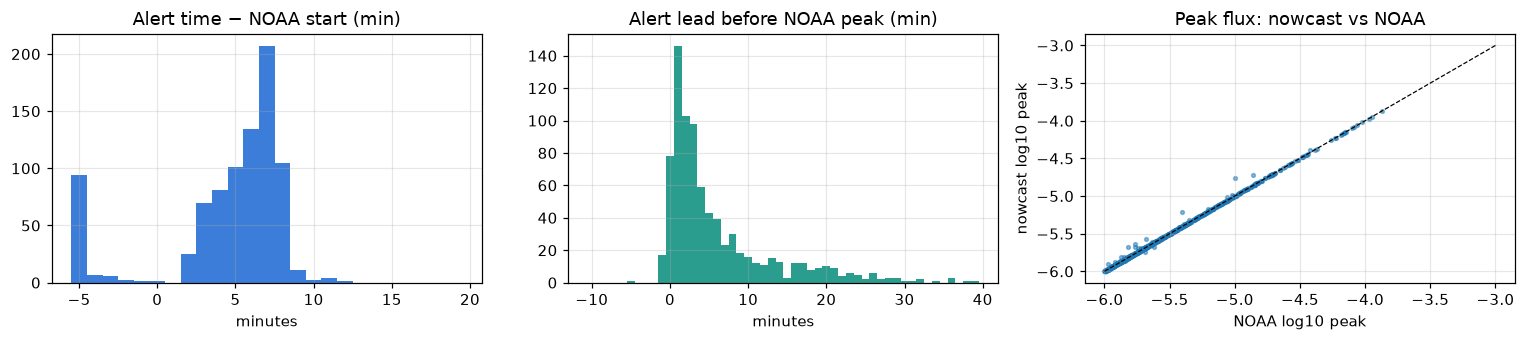

In [9]:
test = reports["TEST May-Oct (held out)"]
print("Held-out POD by NOAA class:")
display(test.by_class.round(3))
hit = test.matched[test.matched["match_idx"] >= 0].copy()
hit = hit[hit["flare_class"].map(class_to_flux) >= 1e-6]
conf = pd.crosstab(hit["flare_class"].str[0], hit["det_class"].str[0], rownames=["NOAA"], colnames=["nowcast"])
print("Class-letter confusion (matched >= C1 flares):"); display(conf)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].hist(hit["alert_latency_min"].clip(-5, 20), bins=np.arange(-5, 21) - 0.5, color="#3b7dd8")
ax[0].set(title="Alert time − NOAA start (min)", xlabel="minutes")
ax[1].hist(hit["alert_before_peak_min"].clip(-10, 40), bins=np.arange(-10, 41) - 0.5, color="#2a9d8f")
ax[1].set(title="Alert lead before NOAA peak (min)", xlabel="minutes")
lf = np.log10(hit["peak_flux"].astype(float)); ld = np.log10(hit["det_peak"].astype(float))
ax[2].scatter(lf, ld, s=6, alpha=0.5); ax[2].plot([-6, -3], [-6, -3], "k--", lw=0.8)
ax[2].set(title="Peak flux: nowcast vs NOAA", xlabel="NOAA log10 peak", ylabel="nowcast log10 peak")
plt.tight_layout(); plt.savefig(FIG / "validation_timing_peaks.png"); plt.show()

### 4a. Baselines on the same held-out period
* **Global 5σ threshold** — the labelling rule of the original forecasting notebook (`counts > mean + 5·std` over the whole dataset).
* **Team Phoenix-style rolling detector** — trailing 2 h median/IQR on linear flux, threshold crossing only (no rise trigger, no onset guard,
  no decay split), 60 s bridging — a faithful analogue of `phase2_background2.py` + `phase3/4`.

In [10]:
def global_sigma_events(series, k=5.0, bridge_min=1, min_dur_min=1):
    thr = series.mean() + k * series.std()
    above = series > thr
    runs, cur = [], None
    for t, a in above.items():
        if a:
            if cur and (t - cur[1]) <= pd.Timedelta(minutes=bridge_min + 1):
                cur[1] = t
            else:
                if cur: runs.append(cur)
                cur = [t, t]
    if cur: runs.append(cur)
    rows = []
    for s, e in runs:
        if (e - s) >= pd.Timedelta(minutes=min_dur_min):
            seg = series[s:e]
            rows.append({"start": s, "end": e, "peak_time": seg.idxmax(), "peak": seg.max(),
                         "detect_time": s, "flare_class": goes_class(seg.max())})
    return pd.DataFrame(rows)

lo, hi = DEV_END, pd.Timestamp("2026-10-28")
r_test = period(ref, "start", lo, hi)
base_global = global_sigma_events(xrs["xrsb"])
team_cfg = ChannelConfig(name="xrsb", model="robust", k_sigma=5.0, min_ratio=1.0, confirm=1, max_dropout_s=60,
                         end_fraction=0.0, rise_in_quiet=False, split_on_rerise=False, rise_samples=10**6,
                         min_count=60, is_goes_flux=True)
team_ev = run_batch(xrs[["xrsb"]], [team_cfg], 60, keep_records=False).events
rows = {}
for name, ev in [("global mean+5σ (old notebook)", base_global), ("Team Phoenix-style rolling", team_ev),
                 ("this engine (tuned)", prim)]:
    rep = evaluate(period(ev, "start", lo, hi), r_test, exclude_days=missing_ref)
    rows[name] = {"precision": rep.precision, "recall(POD) >=C": rep.recall, "F1": rep.f1,
                  "M POD": rep.by_class["POD"].get("M", np.nan), "X POD": rep.by_class["POD"].get("X", np.nan),
                  "median alert latency (min)": rep.timing["alert_latency_median_min"], "flares >=C": rep.n_detected}
baselines = pd.DataFrame(rows).T
baselines.round(3)

,precision,recall(POD) >=C,F1,M POD,X POD,median alert latency (min),flares >=C
global mean+5σ (old notebook),0.963,0.028,0.054,0.232,1.0,9.5,27.0
Team Phoenix-style rolling,0.745,0.731,0.738,0.859,1.0,5.0,922.0
this engine (tuned),0.910,0.910,0.910,0.980,1.0,6.0,937.0


## 5. The four X-flares of the Aditya-L1 window (Team Phoenix `calib_check.py`) and two-channel fusion

,start,peak,flare_class,det_start,det_detect,det_class,alert_latency_min,alert_before_peak_min
161,2026-03-30 02:47:00,2026-03-30 03:19:00,X1.5,2026-03-30 01:57:00,2026-03-30 02:54:00,X1.5,7.0,25.0
373,2026-04-24 00:51:00,2026-04-24 01:07:00,X2.5,2026-04-24 00:51:00,2026-04-24 00:59:00,X2.5,8.0,8.0
377,2026-04-24 08:01:00,2026-04-24 08:14:00,X2.5,2026-04-24 08:01:00,2026-04-24 08:08:00,X2.5,7.0,6.0
734,2026-06-03 11:19:00,2026-06-03 11:28:00,X1.0,2026-06-03 11:19:00,2026-06-03 11:21:00,X1.0,2.0,7.0


fusion labels: {'BOTH': 1842, 'SECONDARY_ONLY': 1209, 'PRIMARY_ONLY': 300}
share confirmed by BOTH channels, by class: {'B': 0.651, 'C': 0.909, 'M': 0.932, 'X': 1.0}


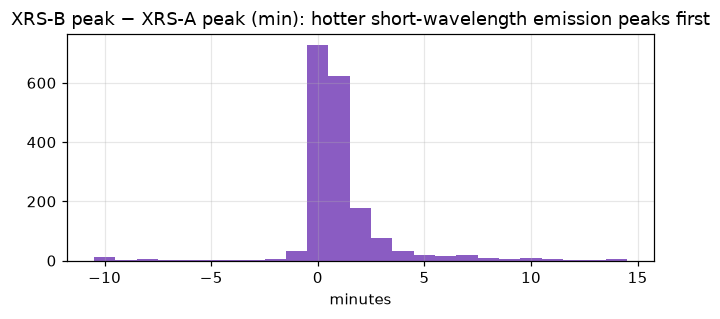

In [11]:
aw = reports["Aditya-L1 window Mar 1-Jun 25"].matched
xa = aw[aw["flare_class"].str[0] == "X"][["start", "peak", "flare_class", "det_start", "det_detect", "det_class", "alert_latency_min", "alert_before_peak_min"]]
display(xa)
fu = res.fused
print("fusion labels:", fu["label"].value_counts().to_dict())
pf = fu[fu["label"] != "SECONDARY_ONLY"].copy(); pf["letter"] = pf["flare_class"].str[0]
print("share confirmed by BOTH channels, by class:", pf.groupby("letter")["label"].apply(lambda s: round((s == "BOTH").mean(), 3)).to_dict())
lag = fu.loc[fu["label"] == "BOTH", "peak_lag_s"] / 60
plt.figure(figsize=(6, 3)); plt.hist(lag.clip(-10, 15), bins=np.arange(-10, 16) - 0.5, color="#8a5cc2")
plt.title("XRS-B peak − XRS-A peak (min): hotter short-wavelength emission peaks first"); plt.xlabel("minutes")
plt.tight_layout(); plt.savefig(FIG / "fusion_peak_lag.png"); plt.show()

## 6. What the engine sees — X1.5 flare of 2026-03-30 and a busy day

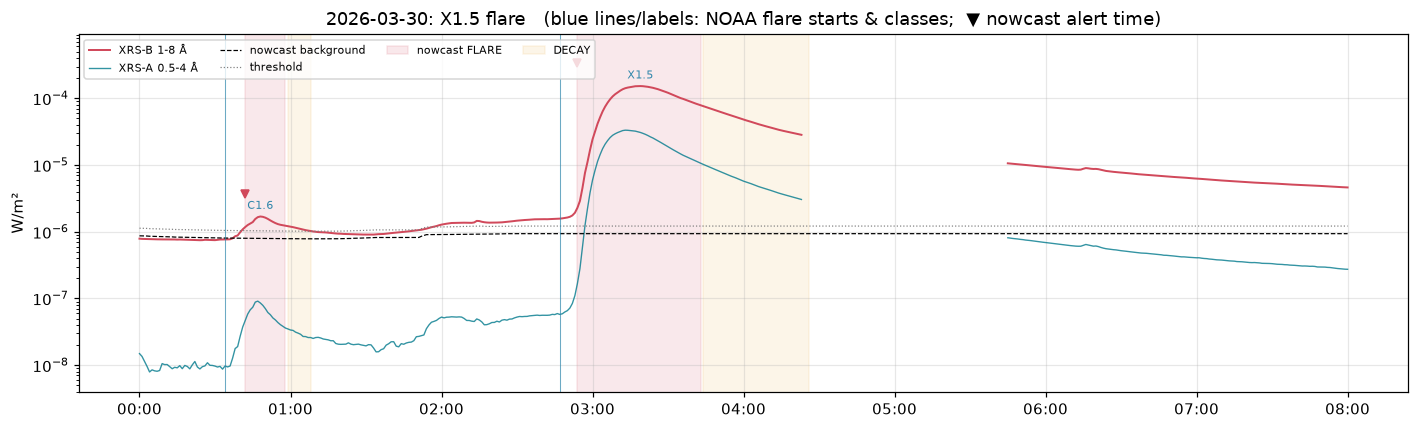

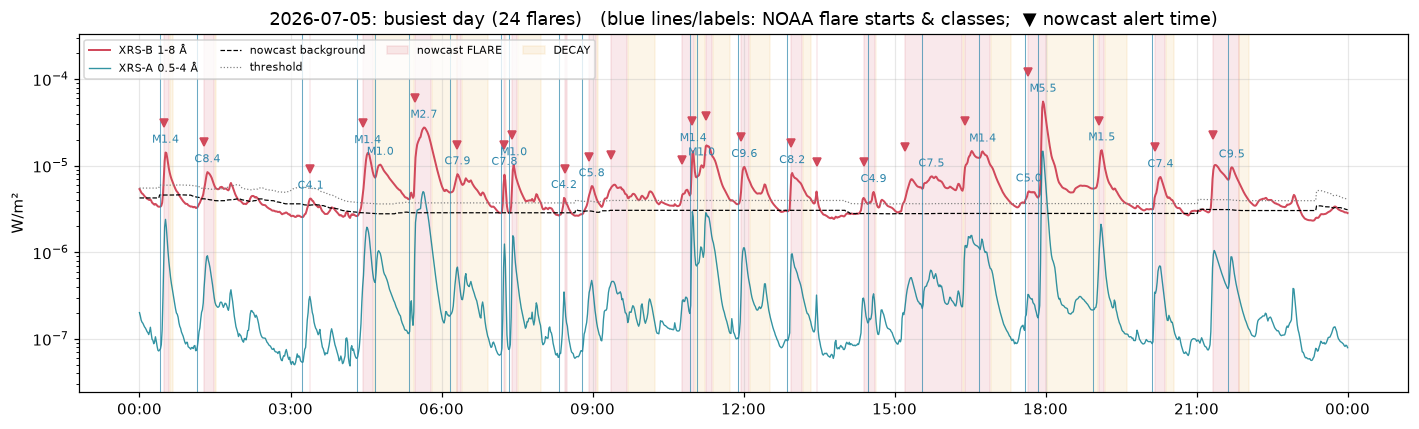

In [12]:
def plot_window(lo, hi, title, fname):
    r = res.records.loc[lo:hi]
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.semilogy(r.index, r["xrsb_value"], color="#d1495b", lw=1.3, label="XRS-B 1-8 Å")
    ax.semilogy(r.index, r["xrsa_value"], color="#00798c", lw=0.9, alpha=0.8, label="XRS-A 0.5-4 Å")
    ax.semilogy(r.index, r["xrsb_background"], color="k", lw=0.8, ls="--", label="nowcast background")
    ax.semilogy(r.index, r["xrsb_threshold"], color="gray", lw=0.8, ls=":", label="threshold")
    st = r["xrsb_state"]
    ax.fill_between(r.index, 1e-9, 1e-2, where=st == FLARE, color="#d1495b", alpha=0.12, step="post", label="nowcast FLARE")
    ax.fill_between(r.index, 1e-9, 1e-2, where=st == DECAY, color="#edae49", alpha=0.12, step="post", label="DECAY")
    for _, f in period(ref, "start", lo, hi).iterrows():
        ax.axvline(f["start"], color="#2e86ab", lw=0.7, alpha=0.7)
        ax.text(f["peak"], f["peak_flux"] * 1.3, f["flare_class"], fontsize=7, ha="center", color="#2e86ab")
    for _, e in period(prim, "start", lo, hi).iterrows():
        ax.plot(e["detect_time"], e["peak"] * 2.2, "v", color="#d1495b", ms=5)
    lo_y = np.nanmin(r["xrsa_value"]) * 0.5 if r["xrsa_value"].notna().any() else 1e-9
    ax.set_ylim(max(lo_y, 1e-9), np.nanmax(r["xrsb_value"]) * 6)
    ax.set(title=title + "   (blue lines/labels: NOAA flare starts & classes;  ▼ nowcast alert time)", ylabel="W/m²")
    ax.legend(loc="upper left", fontsize=7, ncol=4); ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    plt.tight_layout(); plt.savefig(FIG / fname); plt.show()

plot_window("2026-03-30 00:00", "2026-03-30 08:00", "2026-03-30: X1.5 flare", "example_x1p5_20260330.png")
busiest = prim.assign(d=prim["start"].dt.normalize()).groupby("d").size().idxmax()
plot_window(busiest, busiest + pd.Timedelta("24h"), f"{busiest:%Y-%m-%d}: busiest day ({(prim['start'].dt.normalize()==busiest).sum()} flares)", "example_busiest_day.png")

## 7. Streaming = batch (one implementation, verified)
The same week is processed (a) by `run_batch` and (b) sample-by-sample through `NowcastEngine.update`, as a live feed would deliver it.
The catalogues must be identical.

In [13]:
wk = xrs["2026-06-01":"2026-06-07 23:59"]
b = run_batch(wk, CHANNELS, 60)
eng = NowcastEngine(CHANNELS, 60)
live_msgs = []
for s in FrameSource(wk):
    _, m = eng.update(s); live_msgs.extend(m)
live_msgs.extend(eng.finalize())
pd.testing.assert_frame_equal(eng.events(), b.events)
pd.testing.assert_frame_equal(eng.fused(), b.fused)
print(f"identical: {len(b.events)} events, {len(b.fused)} fused flares, {len(live_msgs)} messages")
for m in live_msgs[:8]:
    print(f"  {m['type']:<11} {m['time']}  {m.get('channel', '')} {m.get('event_id', '')} "
          f"{m['event'].flare_class if m['type']=='end' else (m['fused'].label + ' ' + str(m['fused'].flare_class) if m['type']=='fused' else '')}")

identical: 171 events, 108 fused flares, 458 messages
  onset       2026-06-01 03:13:00  xrsa xrsa-00001 
  end         2026-06-01 03:25:00  xrsa xrsa-00001 None
  fused       2026-06-01 03:25:00    SECONDARY_ONLY None
  onset       2026-06-01 03:32:00  xrsa xrsa-00002 
  end         2026-06-01 03:39:00  xrsa xrsa-00002 None
  fused       2026-06-01 03:39:00    SECONDARY_ONLY None
  onset       2026-06-01 03:53:00  xrsa xrsa-00003 
  end         2026-06-01 03:54:00  xrsa xrsa-00003 None


## 8. Real-time capacity for Aditya-L1 cadence
Aditya-L1 SoLEXS/HEL1OS deliver one sample **per second**. The engine must process faster than that.

In [14]:
rng = np.random.default_rng(0)
n = 6 * 3600
idx = pd.date_range("2026-03-01", periods=n, freq="1s")
synthetic = pd.DataFrame({"solexs_counts": rng.poisson(9, n).astype(float), "hel1os_cdte": rng.poisson(0.2, n).astype(float)}, index=idx)
t0 = time.time(); run_batch(synthetic, aditya_channels(), 1, keep_records=False); el = time.time() - t0
print(f"6 h of 1 Hz SoLEXS+HEL1OS ({n:,} samples) in {el:.1f}s -> {n/el:,.0f} samples/s = {n/el:,.0f}x faster than real time")

6 h of 1 Hz SoLEXS+HEL1OS (21,600 samples) in 0.8s -> 25,769 samples/s = 25,769x faster than real time


## 9. Live stream — NOAA SWPC GOES XRS (real, public, updated every minute)
`GOESLiveSource` back-fills the last day (warms the 2-hour background), then polls once a minute and yields only new minutes.
Every new minute goes through the engine and produces messages (`onset`, `escalation`, `end`, `fused`). Set `RUN_LIVE = False` offline.

In [15]:
if RUN_LIVE:
    live_eng = NowcastEngine(CHANNELS, 60)
    src = GOESLiveSource(poll_s=60, backfill="1-day", max_polls=2, on_error=lambda e: print("feed error:", e))
    last, n_live, new_msgs = None, 0, []
    for s in src:
        rec, msgs = live_eng.update(s)
        n_live += 1; last = rec; new_msgs.extend(msgs)
    print(f"received {n_live} live minutes up to {last['time']} UTC")
    print(f"current state: {last['status']} | XRS-B {last['xrsb_value']:.2e} W/m² ({goes_class(last['xrsb_value'])}-level), "
          f"background {last['xrsb_background']:.2e}, threshold {last['xrsb_threshold']:.2e}")
    ended = [m['event'] for m in new_msgs if m['type'] == 'end' and m['channel'] == 'xrsb']
    print(f"flares in the last 24 h: {len(ended)}", [f"{e.flare_class} @ {e.peak_time:%H:%M}" for e in ended][-12:])
else:
    print("RUN_LIVE is False - skipped")

received 1440 live minutes up to 2026-10-28 19:17:00 UTC
current state: QUIET | XRS-B 4.12e-07 W/m² (B4.1-level), background 3.78e-07, threshold 4.91e-07
flares in the last 24 h: 10 ['B6.2 @ 21:19', 'B5.4 @ 00:23', 'B5.9 @ 01:49', 'B7.9 @ 03:23', 'B4.3 @ 04:46', 'B6.0 @ 04:59', 'C1.0 @ 06:13', 'B8.4 @ 08:39', 'B6.3 @ 11:09', 'B6.4 @ 12:52']


## 10. Aditya-L1 path — SoLEXS + HEL1OS
Set `SOLEXS_CSV` / `HEL1OS_CSV` in the configuration cell to the Team Phoenix exports and this section runs on real data:
HEL1OS duplicate rows are dropped and its ~1.6 Hz cadence is binned to 1 Hz (counts **summed**, hardness **averaged**), SoLEXS gaps
become explicit NaN rows, both are aligned on one 1-second grid and run through `aditya_channels()`
(SoLEXS: robust median/IQR model; HEL1OS CdTe: Poisson model — median/MAD collapses to zero on its zero-inflated counts).

Without the files, the cell below writes a **clearly synthetic** test day in the exact Team Phoenix CSV schema into a temporary folder and
streams it through the same path the real pipeline uses (directory watcher → stream aligner → engine) — proving the plumbing, not the science.

In [16]:
import tempfile
if SOLEXS_CSV and HEL1OS_CSV:
    adi = align_frames(read_solexs_csv(SOLEXS_CSV), read_hel1os_csv(HEL1OS_CSV), cadence="1s")
    print("Aditya-L1 grid:", adi.shape, adi.index.min(), "->", adi.index.max())
    adi_res = run_batch(adi[["solexs_counts", "hel1os_cdte"]], aditya_channels(), cadence_s=1)
    adi_res.events.to_csv(OUT / "nowcast_catalogue_aditya_l1.csv", index=False)
    adi_res.fused.to_csv(OUT / "nowcast_fused_aditya_l1.csv", index=False)
    display(adi_res.fused["label"].value_counts())
    # Cross-calibrate SoLEXS counts -> GOES flux on flares seen by both, for real A-X classes:
    soft = adi_res.primary_events("solexs_counts")
    m = match_events(soft.rename(columns={}), period(ref, "start", soft["start"].min(), soft["start"].max()))
    ok = m["match_idx"] >= 0
    calib = fit_counts_to_flux(m.loc[ok, "det_peak"].astype(float), m.loc[ok, "peak_flux"].astype(float))
    print("log10(flux) = %.3f + %.3f log10(counts)" % calib.coefficients)
else:
    tmp = Path(tempfile.mkdtemp(prefix="aditya_demo_"))
    rng = np.random.default_rng(7)
    sec = np.arange(4 * 3600)
    t = pd.Timestamp("2026-03-30 00:00:00")
    flare = np.where(sec >= 3 * 3600, 900 * np.minimum((sec - 3 * 3600) / 420, 1) * np.exp(-np.maximum(sec - 3 * 3600 - 420, 0) / 900), 0)
    counts = rng.poisson(9 + flare)
    hard_burst = np.where((sec >= 3 * 3600 + 60) & (sec < 3 * 3600 + 360), 40, 0)
    # SoLEXS: 1 Hz, written as hourly files (as a sync job would drop them)
    for h in range(4):
        sl = slice(h * 3600, (h + 1) * 3600)
        pd.DataFrame({"time": t + pd.to_timedelta(sec[sl], unit="s"), "counts": counts[sl], "hardness": 1.6}).to_csv(tmp / f"solexs_{h:02d}.csv", index=False)
    # HEL1OS: ~1.6 Hz with the 0.733 s offset and duplicate rows seen in the real export
    ht = np.arange(0, 4 * 3600, 0.6) + 0.733
    hc = rng.poisson(0.12 + np.interp(ht, sec, hard_burst) * 0.6)
    hel = pd.DataFrame({"time": t + pd.to_timedelta(ht, unit="s"), "cdte_broad": hc, "cdte_hardness": 0.5,
                        "czt_broad": rng.poisson(15, len(ht)), "czt_hardness": 0.4})
    pd.concat([hel, hel.sample(2000, random_state=1)]).sort_values("time").to_csv(tmp / "hel1os_full.csv", index=False)

    soft_stream = DirectoryWatchSource(tmp, "solexs_*.csv", read_solexs_csv)       # live mode: poll_s=30
    hard_stream = FrameSource(read_hel1os_csv(tmp / "hel1os_full.csv")[["hel1os_cdte"]])
    aligner = StreamAligner(1.0, {"solexs_counts": "sum", "hel1os_cdte": "sum"}, lateness_s=2.0)
    adi_eng = NowcastEngine(aditya_channels(), cadence_s=1)
    msgs = []
    for s in aligner.run(merge_sources(soft_stream, hard_stream)):
        msgs.extend(adi_eng.update(s)[1])
    msgs.extend(adi_eng.finalize())
    for m in msgs:
        if m["type"] in ("onset", "fused"):
            extra = (f"{m['fused'].label}  soft-peak lag vs hard: {m['fused'].peak_lag_s/60:.1f} min" if m["type"] == "fused" else m["channel"])
            print(f"{m['type']:<6} {m['time']}  {extra}")
    print("(synthetic demonstration data - replace with SOLEXS_CSV / HEL1OS_CSV for the real catalogue)")

onset  2026-03-30 03:00:16  solexs_counts
onset  2026-03-30 03:01:04  hel1os_cdte
fused  2026-03-30 03:17:26  BOTH  soft-peak lag vs hard: 3.8 min
(synthetic demonstration data - replace with SOLEXS_CSV / HEL1OS_CSV for the real catalogue)


## 11. Export

In [17]:
prim.to_csv(OUT / "nowcast_catalogue_goes19_2026.csv", index=False)
res.fused.to_csv(OUT / "nowcast_fused_goes19_2026.csv", index=False)
summary.to_csv(OUT / "validation_summary.csv")
baselines.to_csv(OUT / "validation_baselines_test.csv")
test.by_class.to_csv(OUT / "validation_pod_by_class_test.csv")
config = {"satellite": f"GOES-{GOES_SATELLITE}", "cadence_s": 60, "tuned_on": f"{START} .. {DEV_END.date()} (excl.)",
          "channels": [c.to_dict() for c in CHANNELS], "fusion_tolerance_s": 300}
(OUT / "nowcast_config.json").write_text(json.dumps(config, indent=2))
print("wrote:", sorted(p.name for p in OUT.iterdir() if p.is_file()))

wrote: ['nowcast_catalogue_goes19_2026.csv', 'nowcast_config.json', 'nowcast_fused_goes19_2026.csv', 'validation_baselines_test.csv', 'validation_pod_by_class_test.csv', 'validation_summary.csv']


In [18]:
t = reports["TEST May-Oct (held out)"]
print("=" * 78)
print(" NOWCAST - held-out test, May 1 - Oct 27 2026 (GOES-19 XRS vs NOAA official flare list)")
print("=" * 78)
print(f" NOAA flares >= C1.0 detected (POD)      : {t.recall:.1%}  ({int(round(t.recall * t.n_reference))}/{t.n_reference})")
for L in ["C", "M", "X"]:
    if L in t.by_class.index:
        r = t.by_class.loc[L]; print(f"   class {L}: {int(r.n_detected)}/{int(r.n_reference)}  ({r.POD:.1%})")
print(f" our >= C1 flares that are NOAA flares    : {t.precision:.1%}   F1 = {t.f1:.3f}")
print(f" class letter agrees with NOAA            : {t.class_agreement:.1%}")
print(f" median alert time after NOAA start       : {t.timing['alert_latency_median_min']:.0f} min "
      f"(alert comes a median {t.timing['alert_before_peak_median_min']:.0f} min before the peak)")
print("=" * 78)

 NOWCAST - held-out test, May 1 - Oct 27 2026 (GOES-19 XRS vs NOAA official flare list)
 NOAA flares >= C1.0 detected (POD)      : 91.0%  (852/936)
   class C: 752/834  (90.2%)
   class M: 97/99  (98.0%)
   class X: 3/3  (100.0%)
 our >= C1 flares that are NOAA flares    : 91.0%   F1 = 0.910
 class letter agrees with NOAA            : 99.9%
 median alert time after NOAA start       : 6 min (alert comes a median 3 min before the peak)
